# Task 5 — EWMA Volatility-Scaled Historical Simulation
### QFI Internship · Market Risk Project · Phase 5
**Prepared by:** Arham Shah

---

**Objective.** Keep the empirical tail shape from Task 4, but make the scenarios respond to the current volatility regime. Each historical shock is replayed at *today's* volatility, as in the Hull–White filtered-HS method.

**What this notebook delivers**
- A vectorised **EWMA (λ = 0.94)** volatility engine, checked against the textbook recursion
- Proof that the filter works: standardised shocks lose their **volatility clustering** (Ljung–Box test)
- Rolling **EWMA-FHS VaR and ES** on the same 9 window × confidence grid as Task 4
- A head-to-head with HS: exceptions, Basel traffic light, reaction speed, and an **exact decomposition** testing whether scaling really removes the ghost effect
- **λ sensitivity** (0.90–0.99), scored on exceptions, VaR stability and QLIKE forecast loss
- Export to `EWMA_VaR.csv` and the shared `VaR_Model_Summary.csv`

> **Pipeline:** Task 1 Data → Task 2 Cleaning → Task 3 Portfolio → Task 4 HS VaR → **Task 5 EWMA-FHS** → Task 6 GARCH-FHS → Task 7 → → Task 8 Backtesting → Task 9 Comparison

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. Why scale historical returns by volatility?
HS gives every day in the window equal weight. Volatility, though, **clusters**: calm and stormy periods each tend to persist. As a result:
1. When stress starts, a few new losses can't move a percentile built mostly on calm days, so exceptions bunch up.
2. After stress ends, old crash days keep VaR high, then drop out all at once (the ghost effect from Task 4). Volatility scaling is often said to fix this, and Section 6 tests that claim on our data.

**EWMA volatility** reacts smoothly, and no observation ever leaves a window abruptly:
$$\sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1-\lambda)\,r_{t-1}^2,\qquad \lambda = 0.94\;\Rightarrow\;\text{half-life} = \ln 0.5/\ln\lambda \approx 11\text{ days}$$

**Hull–White filtering** separates the *size* of a shock from the *regime* it happened in:
$$z_i = \frac{r_i}{\sigma_i}\quad\Rightarrow\quad \tilde r_{i\to t} = z_i\,\sigma_t,\qquad \text{VaR}_t = -\sigma_t\,Q_{1-c}(z_{t-W},\dots,z_{t-1})$$

A −5% day from a 40%-vol regime counts as a −2.5% day if today's volatility is 20%, and the other way round. The tail *shape* stays empirical and non-Normal, and only the *scale* adapts. σ_t uses returns up to t − 1, so the VaR is still a genuine forecast.

## Conventions used in every VaR task (4 → 9)
| Convention | Choice | Why |
|---|---|---|
| Horizon | 1 trading day | Standard for daily risk limits and backtesting |
| Timing | VaR for day *t* uses data up to *t − 1* only | No look-ahead, so it is a genuine forecast that can be backtested |
| Sign | VaR and ES are **positive losses** | Easier to read: "we could lose $X" |
| Units | Model on **returns**, then convert to dollars with the **start-of-day value** | The portfolio grew from $1M to $4.5M, so old dollar P&L understates today's risk |
| Exception | Return < −VaR (equivalently P&L < −VaR$) | Basel definition |
| Headline | 99% confidence, 250-day window | Basel internal-models standard |
| Export | `<MODEL>_VaR.csv` with identical column patterns | Task 8 and Task 9 can read every model the same way |

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. Load the Task 3 portfolio and the shared toolkit

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


## 3. EWMA volatility engine
The recursion is a linear filter, so we run it with `scipy.signal.lfilter`, which is exact and fast, and check it against an explicit loop. The variance is seeded with the average squared return over the first 30 days. That burn-in is far shorter than the shortest 250-day VaR window.

In [5]:
SEED = 30
def ewma_sigma(r, lam=EWMA_LAMBDA, seed=SEED):
    """sigma_t from r_0..r_{t-1} (one-day-ahead). Returns a Series aligned to r."""
    e2 = np.asarray(r, float) ** 2
    h0 = e2[:seed].mean()
    h = np.r_[h0, lfilter([1 - lam], [1, -lam], e2[:-1], zi=[lam * h0])[0]]
    return pd.Series(np.sqrt(h), index=r.index, name='EWMA_Vol')

def ewma_next(r, lam=EWMA_LAMBDA):
    """Forecast for the day AFTER the last observation."""
    s = ewma_sigma(r, lam)
    return float(np.sqrt(lam * s.iloc[-1] ** 2 + (1 - lam) * r.iloc[-1] ** 2))

sigma = ewma_sigma(returns)
# validation against the textbook loop
h = np.empty(len(returns)); h[0] = (returns.iloc[:SEED] ** 2).mean()
for t in range(1, len(returns)):
    h[t] = EWMA_LAMBDA * h[t - 1] + (1 - EWMA_LAMBDA) * returns.iloc[t - 1] ** 2
assert np.allclose(np.sqrt(h), sigma)
half_life = np.log(0.5) / np.log(EWMA_LAMBDA)
print(f'EWMA engine validated | lambda = {EWMA_LAMBDA} | half-life = {half_life:.1f} days | '
      f'weight on yesterday = {1 - EWMA_LAMBDA:.0%}')

ann = np.sqrt(TRADING_DAYS)
vol_tbl = pd.DataFrame({
    'EWMA (0.94)': [sigma.iloc[-1] * ann, ewma_next(returns) * ann, sigma.iloc[SEED:].mean() * ann, sigma.iloc[SEED:].max() * ann],
    'Rolling 250d': [returns.iloc[-250:].std() * ann, np.nan, returns.rolling(250).std().mean() * ann, returns.rolling(250).std().max() * ann],
}, index=['Latest', 'Next-day forecast', 'Average', 'Maximum'])
vol_tbl.style.format('{:.1%}', na_rep='-')

EWMA engine validated | lambda = 0.94 | half-life = 11.2 days | weight on yesterday = 6%


,EWMA (0.94),Rolling 250d
Latest,19.5%,16.3%
Next-day forecast,18.9%,-
Average,21.7%,22.8%
Maximum,58.9%,33.4%


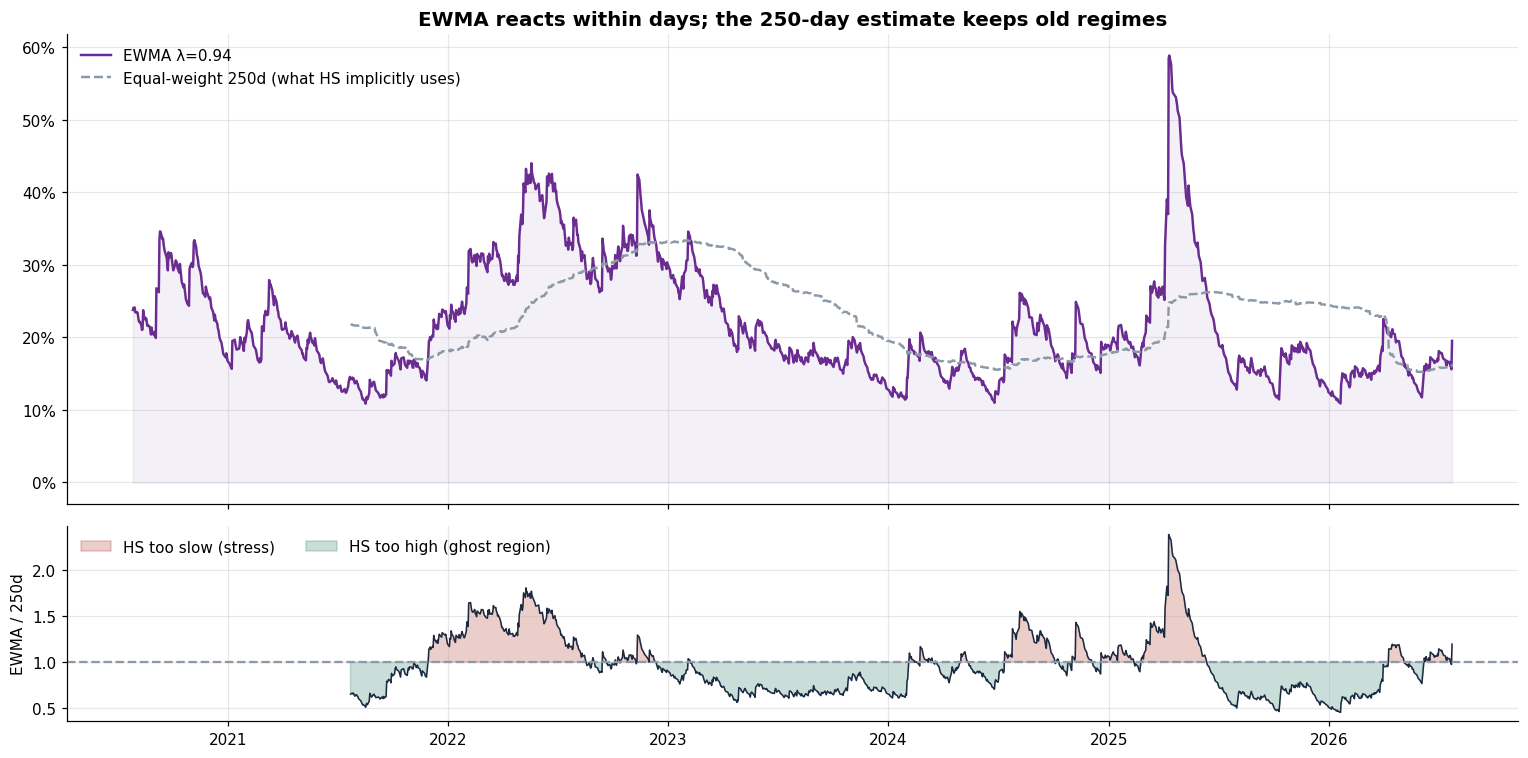

EWMA vol was above the 250d estimate on 41% of days and more than 1.5x it on 7.6%.


In [6]:
roll250 = returns.rolling(250).std().shift(1)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [2.4, 1]})
ax.plot(sigma * ann, color=COLORS['EWMA'], lw=1.6, label=f'EWMA λ={EWMA_LAMBDA}')
ax.plot(roll250 * ann, color=COLORS['muted'], lw=1.6, ls='--', label='Equal-weight 250d (what HS implicitly uses)')
ax.fill_between(sigma.index, 0, sigma * ann, color=COLORS['EWMA'], alpha=0.07)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(loc='upper left')
ax.set_title('EWMA reacts within days; the 250-day estimate keeps old regimes')
ratio = (sigma / roll250).dropna()
ax2.plot(ratio, color=COLORS['ink'], lw=1); ax2.axhline(1, color=COLORS['muted'], ls='--')
ax2.fill_between(ratio.index, 1, ratio, where=ratio >= 1, color=COLORS['loss'], alpha=0.25, label='HS too slow (stress)')
ax2.fill_between(ratio.index, 1, ratio, where=ratio < 1, color=COLORS['gain'], alpha=0.25, label='HS too high (ghost region)')
ax2.set_ylabel('EWMA / 250d'); ax2.legend(ncol=2, loc='upper left')
plt.tight_layout(); plt.show()
print(f'EWMA vol was above the 250d estimate on {(ratio > 1).mean():.0%} of days and more than 1.5x it on {(ratio > 1.5).mean():.1%}.')

## 4. Does the filter work? Diagnostics on the standardised shocks
If EWMA captures the volatility dynamics, the standardised shocks z = r/σ should have variance ≈ 1 and **no remaining clustering**. The autocorrelation of z² should be close to zero, while r² shows strong autocorrelation.

,Raw returns r,Standardised z = r/σ
Std. dev. (relative / target 1),1.000,1.038
Excess kurtosis,4.491,1.519
Ljung-Box Q(10) on squares,172.217,6.945
p-value,0.000,0.731


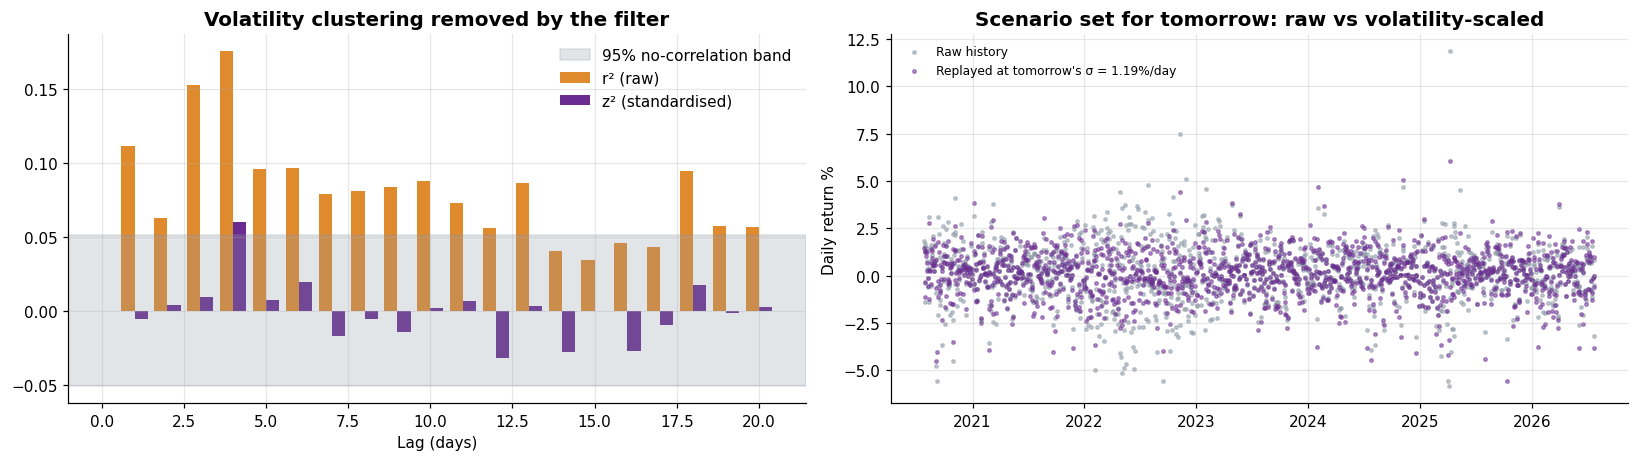

In [7]:
z = (returns / sigma).iloc[SEED:]
r_ = returns.iloc[SEED:]
diag = pd.DataFrame({
    'Raw returns r': [r_.std() / r_.std(), r_.kurt(), *ljung_box(r_ ** 2, 10)],
    'Standardised z = r/σ': [z.std(), z.kurt(), *ljung_box(z ** 2, 10)],
}, index=['Std. dev. (relative / target 1)', 'Excess kurtosis', 'Ljung-Box Q(10) on squares', 'p-value'])
display(diag.style.format('{:.3f}'))

def acf(x, lags=20):
    x = np.asarray(x) - np.mean(x); d = x @ x
    return np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 4.3))
L = np.arange(1, 21); ci = 1.96 / np.sqrt(len(z))
a0.bar(L - 0.2, acf(r_ ** 2), 0.4, color=COLORS['HS'], label='r² (raw)')
a0.bar(L + 0.2, acf(z ** 2), 0.4, color=COLORS['EWMA'], label='z² (standardised)')
a0.axhspan(-ci, ci, color=COLORS['muted'], alpha=0.25, label='95% no-correlation band')
a0.set_title('Volatility clustering removed by the filter'); a0.set_xlabel('Lag (days)'); a0.legend()
a1.scatter(returns.index, returns * 100, s=5, color=COLORS['muted'], alpha=0.5, label='Raw history')
a1.scatter(returns.index, returns / sigma * ewma_next(returns) * 100, s=5, color=COLORS['EWMA'], alpha=0.5,
           label=f'Replayed at tomorrow\'s σ = {pct(ewma_next(returns))}/day')
a1.set_title('Scenario set for tomorrow: raw vs volatility-scaled'); a1.set_ylabel('Daily return %'); a1.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Rolling EWMA-FHS VaR and ES
These use the same windows, confidence levels and timing as Task 4, so any difference comes from the volatility scaling alone. HS is recomputed with the shared toolkit and checked against `HS_VaR.csv` from Task 4 if that file exists.

In [8]:
EWMA = {(w, c): rolling_fhs(returns, sigma, w, c) for w in WINDOWS for c in CONFIDENCES}
HS   = {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}

if os.path.exists('HS_VaR.csv'):
    t4 = pd.read_csv('HS_VaR.csv', index_col=0, parse_dates=True)
    col = f'HS_VaR_{HEADLINE_W}d_{tag(HEADLINE_CL)}_Ret'
    assert np.allclose(t4[col].dropna(), HS[(HEADLINE_W, HEADLINE_CL)]['VaR'].dropna()), 'HS mismatch vs Task 4'
    print('Consistency check passed: HS forecasts identical to Task 4 output.')

# next-day forecasts (for tomorrow, using data through today)
s_next = ewma_next(returns)
z_all = returns / sigma
NEXT = {(w, c): tuple(s_next * np.array(var_es(z_all.iloc[-w:], c))) for w in WINDOWS for c in CONFIDENCES}
NEXT_HS = {(w, c): var_es(returns.iloc[-w:], c) for w in WINDOWS for c in CONFIDENCES}
nx = pd.DataFrame({f'{w}d / {c:.1%}': {'HS VaR $': NEXT_HS[(w, c)][0] * NAV, 'EWMA VaR $': NEXT[(w, c)][0] * NAV,
                                         'HS ES $': NEXT_HS[(w, c)][1] * NAV, 'EWMA ES $': NEXT[(w, c)][1] * NAV}
                   for w in WINDOWS for c in CONFIDENCES}).T
nx['EWMA vs HS'] = nx['EWMA VaR $'] / nx['HS VaR $'] - 1
print(f'Next-day risk on NAV {money(NAV)}:')
nx.style.format({c: '${:,.0f}' for c in nx.columns[:4]} | {'EWMA vs HS': '{:+.1%}'})

Consistency check passed: HS forecasts identical to Task 4 output.
Next-day risk on NAV $4,520,228:


,HS VaR $,EWMA VaR $,HS ES $,EWMA ES $,EWMA vs HS
250d / 95.0%,"$74,562","$95,579","$107,635","$144,568",+28.2%
250d / 99.0%,"$126,797","$173,974","$143,752","$208,775",+37.2%
250d / 99.5%,"$141,587","$194,067","$147,824","$226,082",+37.1%
500d / 95.0%,"$95,210","$92,541","$139,588","$141,584",-2.8%
500d / 99.0%,"$152,264","$173,784","$212,286","$200,289",+14.1%
500d / 99.5%,"$188,628","$187,587","$237,110","$214,110",-0.6%
750d / 95.0%,"$84,376","$89,788","$127,257","$134,839",+6.4%
750d / 99.0%,"$146,470","$172,475","$192,295","$193,917",+17.8%
750d / 99.5%,"$178,876","$186,283","$223,768","$211,053",+4.1%


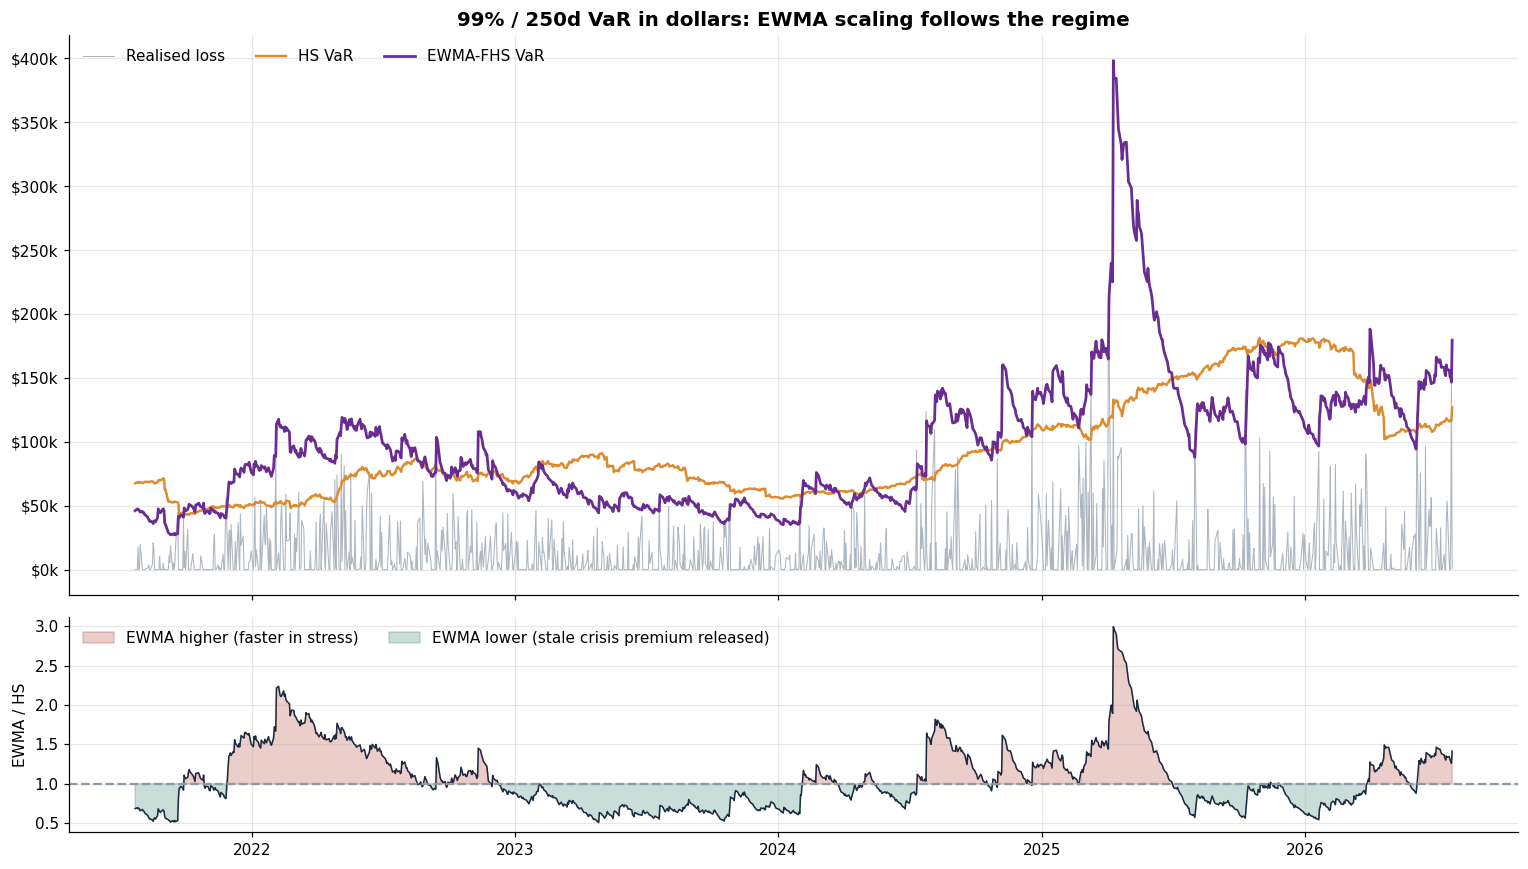

In [9]:
w, c = HEADLINE_W, HEADLINE_CL
hs_d, ew_d = HS[(w, c)]['VaR'] * start_value, EWMA[(w, c)]['VaR'] * start_value
common = hs_d.dropna().index
loss = -pnl
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2.6, 1]})
ax.plot(common, loss.loc[common].clip(lower=0), color=COLORS['muted'], lw=0.7, alpha=0.7, label='Realised loss')
ax.plot(hs_d.loc[common], color=COLORS['HS'], lw=1.6, label='HS VaR')
ax.plot(ew_d.loc[common], color=COLORS['EWMA'], lw=1.8, label='EWMA-FHS VaR')
ax.yaxis.set_major_formatter(usd_fmt); ax.legend(ncol=3, loc='upper left')
ax.set_title(f'{c:.0%} / {w}d VaR in dollars: EWMA scaling follows the regime')
vr = (ew_d / hs_d).loc[common]
ax2.plot(vr, color=COLORS['ink'], lw=1); ax2.axhline(1, color=COLORS['muted'], ls='--')
ax2.fill_between(vr.index, 1, vr, where=vr >= 1, color=COLORS['loss'], alpha=0.25, label='EWMA higher (faster in stress)')
ax2.fill_between(vr.index, 1, vr, where=vr < 1, color=COLORS['gain'], alpha=0.25, label='EWMA lower (stale crisis premium released)')
ax2.set_ylabel('EWMA / HS'); ax2.legend(ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

## 6. Does scaling remove the ghost effect? A test, not an assumption
EWMA-FHS VaR is σ_t × q_t, where q_t is the quantile of the trailing standardised shocks. Each daily change splits **exactly** into two parts:
$$\Delta\text{VaR}_t = \underbrace{q_{t-1}\,\Delta\sigma_t}_{\text{news: volatility update}} + \underbrace{\sigma_t\,\Delta q_t}_{\text{window composition (ghost-type)}}$$
For plain HS the whole change is window composition. If scaling helps, EWMA's composition part should be small on the days when HS has ghost jumps.

In [10]:
W, c = HEADLINE_W, HEADLINE_CL
hv, ev = HS[(W, c)]['VaR'], EWMA[(W, c)]['VaR']
qz = ev / sigma
ok = hv.notna() & hv.shift(1).notna()
comp_hs = hv.diff()[ok]
news_ew = (qz.shift(1) * sigma.diff())[ok]
comp_ew = (sigma * qz.diff())[ok]
assert np.allclose(news_ew + comp_ew, ev.diff()[ok])              # exact decomposition

quiet = (returns.shift(1).abs() < 0.01)[ok]
ghosts = comp_hs[quiet].nsmallest(8).index                       # the 8 worst HS ghost days
gt = pd.DataFrame({'Shock leaving window': [returns.index[returns.index.get_loc(t) - W - 1].date() for t in ghosts],
                   'Shock return': [returns.iloc[returns.index.get_loc(t) - W - 1] for t in ghosts],
                   'Vol then (ann.)': [sigma.iloc[returns.index.get_loc(t) - W - 1] * ann for t in ghosts],
                   'HS ΔVaR': comp_hs[ghosts].values, 'EWMA composition ΔVaR': comp_ew[ghosts].values,
                   'EWMA news ΔVaR': news_ew[ghosts].values}, index=pd.Index([t.date() for t in ghosts], name='Ghost day'))
gt['Ghost reduced by'] = 1 - gt['EWMA composition ΔVaR'] / gt['HS ΔVaR']
display(gt.style.format({'Shock return': '{:.2%}', 'Vol then (ann.)': '{:.0%}', 'HS ΔVaR': '{:+.2%}',
                         'EWMA composition ΔVaR': '{:+.2%}', 'EWMA news ΔVaR': '{:+.2%}', 'Ghost reduced by': '{:.0%}'})
        .background_gradient(subset=['Ghost reduced by'], cmap='Greens', vmin=0, vmax=1))

share_news = news_ew.abs().sum() / (news_ew.abs().sum() + comp_ew.abs().sum())
GHOST_RED = gt['Ghost reduced by'].median()
print(f'On the 8 worst HS ghost days, EWMA-FHS cut the ghost jump by a median {GHOST_RED:.0%} '
      f'(range {gt["Ghost reduced by"].min():.0%} to {gt["Ghost reduced by"].max():.0%}).')
print(f'Average size of composition jumps over all days: HS {comp_hs.abs().mean():.3%} | EWMA {comp_ew.abs().mean():.3%}')
print(f'{share_news:.0%} of all EWMA-FHS VaR movement comes from volatility NEWS, not window composition.')

,Shock leaving window,Shock return,Vol then (ann.),HS ΔVaR,EWMA composition ΔVaR,EWMA news ΔVaR,Ghost reduced by
Ghost day,,,,,,,
2021-09-07,2020-09-08,-5.59%,26%,-0.56%,-0.32%,-0.06%,42%
2021-09-22,2020-09-23,-3.67%,29%,-0.51%,+0.00%,-0.07%,100%
2021-09-02,2020-09-03,-4.77%,20%,-0.49%,-0.48%,-0.08%,1%
2026-03-10,2025-03-10,-4.28%,22%,-0.45%,+0.00%,-0.04%,100%
2023-08-28,2022-08-26,-4.05%,27%,-0.44%,-0.16%,-0.06%,64%
2026-04-06,2025-04-03,-5.59%,25%,-0.43%,-0.46%,-0.13%,-6%
2023-05-09,2022-05-09,-4.92%,40%,-0.43%,+0.00%,-0.08%,100%
2026-04-21,2025-04-21,-3.21%,53%,-0.37%,+0.00%,-0.09%,100%


On the 8 worst HS ghost days, EWMA-FHS cut the ghost jump by a median 82% (range -6% to 100%).
Average size of composition jumps over all days: HS 0.009% | EWMA 0.011%
92% of all EWMA-FHS VaR movement comes from volatility NEWS, not window composition.


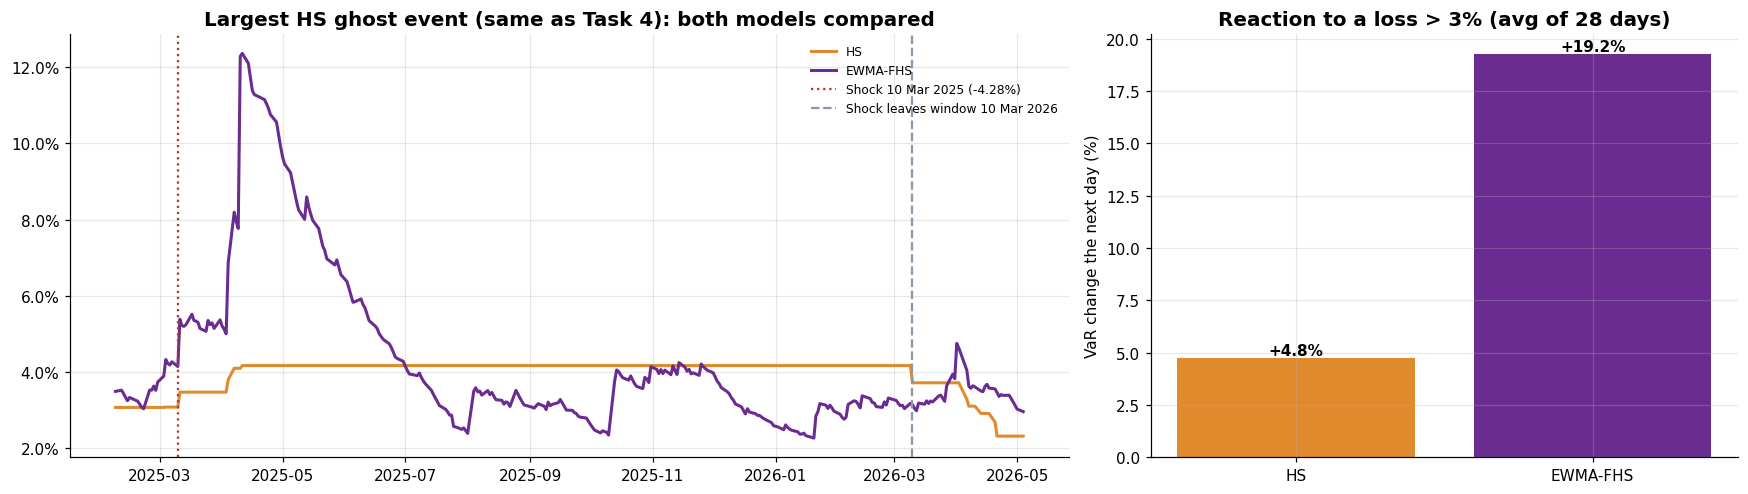

The day after a >3% loss, HS VaR rises +4.8% on average and EWMA-FHS VaR rises +19.2%.


In [11]:
# Responsiveness: how fast does each model react after a large loss?
big = returns[(returns < -0.03) & ok].index
pos = [returns.index.get_loc(t) for t in big if returns.index.get_loc(t) + 1 < len(returns)]
react = pd.DataFrame({'HS': [hv.iloc[p + 1] / hv.iloc[p] - 1 for p in pos],
                      'EWMA-FHS': [ev.iloc[p + 1] / ev.iloc[p] - 1 for p in pos]}, index=returns.index[pos])
REACT = react.mean()
t_star = [t for t in ghosts if returns.index.get_loc(t) >= 2 * W + 1][0]   # same rule as Task 4
p = returns.index.get_loc(t_star) - W - 1
sl = slice(max(0, p - 20), p + W + 40)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.7, 1]})
a0.plot(hv.iloc[sl], color=COLORS['HS'], lw=2, label='HS')
a0.plot(ev.iloc[sl], color=COLORS['EWMA'], lw=2, label='EWMA-FHS')
a0.axvline(returns.index[p], color=COLORS['loss'], ls=':', label=f'Shock {returns.index[p]:%d %b %Y} ({pct(returns.iloc[p])})')
a0.axvline(t_star, color=COLORS['muted'], ls='--', label=f'Shock leaves window {t_star:%d %b %Y}')
a0.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a0.legend(fontsize=8, loc='upper right')
a0.set_title('Largest HS ghost event (same as Task 4): both models compared')
a1.bar(['HS', 'EWMA-FHS'], REACT.values * 100, color=[COLORS['HS'], COLORS['EWMA']])
for i, v in enumerate(REACT.values * 100): a1.text(i, v, f'{v:+.1f}%', ha='center', va='bottom', fontweight='bold')
a1.set_ylabel('VaR change the next day (%)'); a1.set_title(f'Reaction to a loss > 3% (avg of {len(react)} days)')
plt.tight_layout(); plt.show()
print(f'The day after a >3% loss, HS VaR rises {REACT["HS"]:+.1%} on average and EWMA-FHS VaR rises {REACT["EWMA-FHS"]:+.1%}.')

**Reading the result.** Scaling reduces a ghost jump only when the exiting crash happened in a *high-volatility* period, because then its standardised shock z = r/σ was moderate. A crash in a calm period is still an extreme z, so it still leaves a mark when it exits. The real gain from EWMA is **reaction speed**: VaR rises sharply the day after a big loss instead of waiting for the loss to move a percentile.

## 7. Exceptions: HS vs EWMA-FHS on identical dates

In [12]:
bt_hs = backtest_table('HS', HS)
bt_ew = backtest_table('EWMA', EWMA)
cmp = bt_hs[['Window', 'Confidence', 'Days', 'Expected']].copy()
for name, b in [('HS', bt_hs), ('EWMA', bt_ew)]:
    cmp[f'{name} exc.'] = b['Exceptions'].values
    cmp[f'{name} Kupiec p'] = b['Kupiec p'].values
    cmp[f'{name} avg VaR'] = b['Avg VaR %'].values
    cmp[f'{name} churn'] = b['VaR churn %'].values
(cmp.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'HS Kupiec p': '{:.3f}', 'EWMA Kupiec p': '{:.3f}',
                   'HS avg VaR': '{:.2%}', 'EWMA avg VaR': '{:.2%}', 'HS churn': '{:.3%}', 'EWMA churn': '{:.3%}'})
    .map(lambda v: 'color:#B03A2E;font-weight:bold' if isinstance(v, float) and v < 0.05 else '', subset=['HS Kupiec p', 'EWMA Kupiec p'])
    .hide(axis='index'))

Window,Confidence,Days,Expected,HS exc.,HS Kupiec p,HS avg VaR,HS churn,EWMA exc.,EWMA Kupiec p,EWMA avg VaR,EWMA churn
250,95.0%,1256,62.8,70,0.360,2.26%,0.007%,67,0.590,2.27%,0.077%
250,99.0%,1256,12.6,22,0.016,3.53%,0.009%,18,0.147,3.73%,0.128%
250,99.5%,1256,6.3,16,0.001,4.01%,0.011%,12,0.042,4.18%,0.137%
500,95.0%,1006,50.3,47,0.629,2.32%,0.003%,48,0.737,2.15%,0.071%
500,99.0%,1006,10.1,10,0.985,3.95%,0.004%,14,0.239,3.51%,0.117%
500,99.5%,1006,5.0,6,0.674,4.37%,0.004%,8,0.222,4.14%,0.136%
750,95.0%,756,37.8,28,0.087,2.33%,0.003%,44,0.313,1.88%,0.063%
750,99.0%,756,7.6,4,0.153,3.83%,0.003%,15,0.016,3.12%,0.106%
750,99.5%,756,3.8,2,0.313,4.56%,0.002%,7,0.138,3.80%,0.127%


`churn` is the average absolute day-to-day change in VaR. It is the price of responsiveness: a limit that moves more makes capital planning harder.

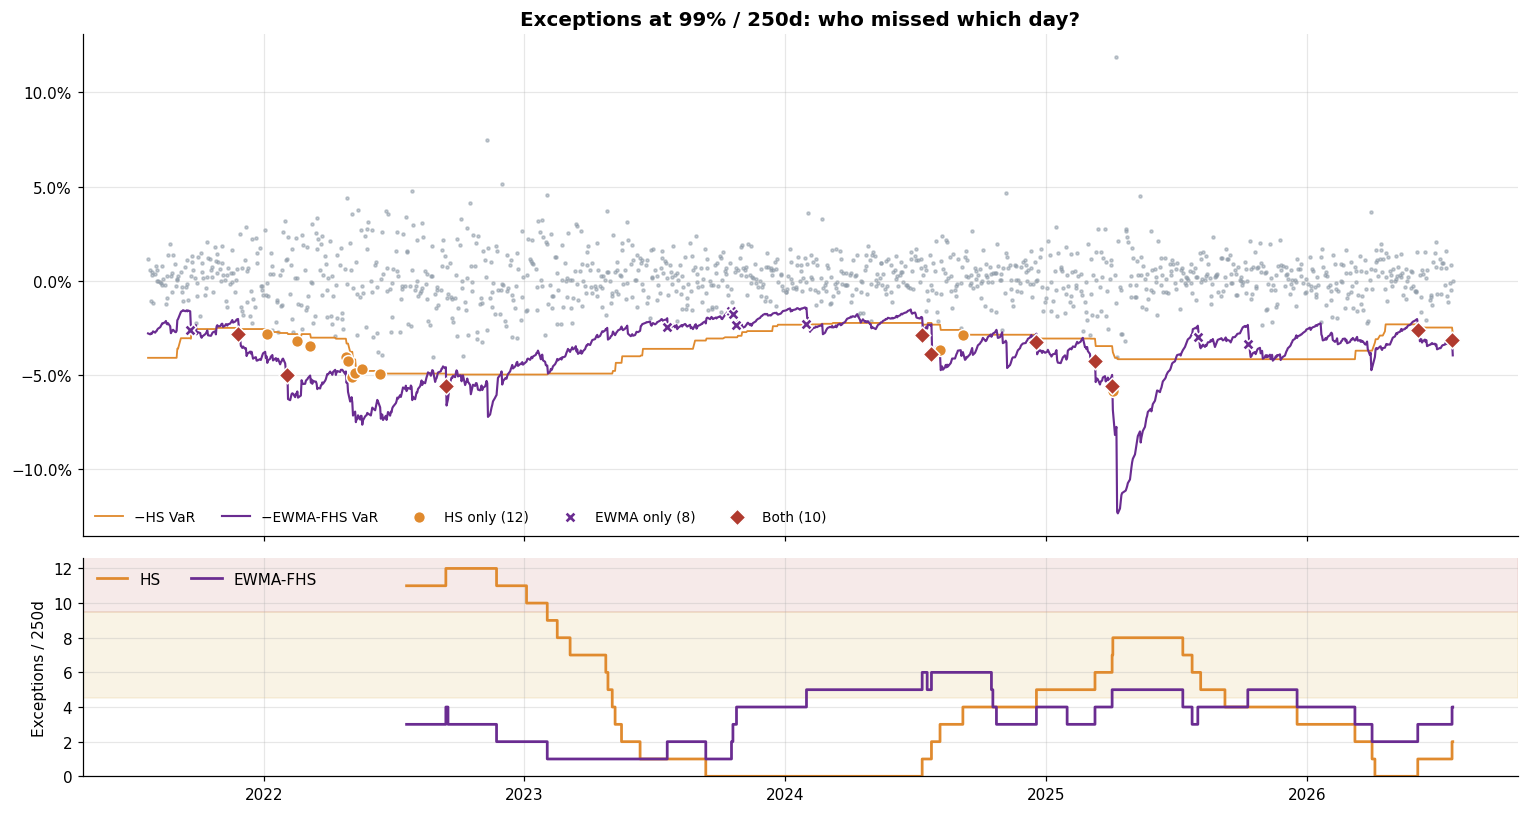

In [13]:
w, c = HEADLINE_W, HEADLINE_CL
mask = HS[(w, c)]['VaR'].notna()
hsb = (returns < -HS[(w, c)]['VaR'])[mask]; ewb = (returns < -EWMA[(w, c)]['VaR'])[mask]
both, hs_only, ew_only = hsb & ewb, hsb & ~ewb, ewb & ~hsb
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={'height_ratios': [2.3, 1]})
r_m = returns[mask]
ax.plot(-HS[(w, c)]['VaR'][mask], color=COLORS['HS'], lw=1.2, label='−HS VaR')
ax.plot(-EWMA[(w, c)]['VaR'][mask], color=COLORS['EWMA'], lw=1.4, label='−EWMA-FHS VaR')
ax.scatter(r_m.index, r_m, s=4, color=COLORS['muted'], alpha=0.5)
for sel, mk, col, lab in [(hs_only, 'o', COLORS['HS'], 'HS only'), (ew_only, 'X', COLORS['EWMA'], 'EWMA only'), (both, 'D', COLORS['loss'], 'Both')]:
    ax.scatter(r_m.index[sel], r_m[sel], s=60, marker=mk, color=col, edgecolor='white', zorder=5, label=f'{lab} ({sel.sum()})')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(ncol=5, fontsize=9, loc='lower left')
ax.set_title(f'Exceptions at {c:.0%} / {w}d: who missed which day?')
for b, col, lab in [(hsb, COLORS['HS'], 'HS'), (ewb, COLORS['EWMA'], 'EWMA-FHS')]:
    ax2.step(b.index, b.astype(int).rolling(250, min_periods=250).sum(), where='post', color=col, lw=1.8, label=lab)
ax2.axhspan(4.5, 9.5, color='#C78B00', alpha=0.1); ax2.axhspan(9.5, 20, color='#B03A2E', alpha=0.1)
ax2.set_ylim(0, max(12, ax2.get_ylim()[1])); ax2.set_ylabel('Exceptions / 250d'); ax2.legend(ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

## 8. λ sensitivity: is 0.94 the right decay?
λ = 0.94 is a RiskMetrics convention from 1996, not a fitted value. Here several values are compared on four criteria:
- **Exceptions and Kupiec p**: is the coverage right?
- **Average VaR**: how much capital does it cost?
- **Churn**: how stable is the limit?
- **QLIKE** = mean(r²/σ² + ln σ²): the standard loss function for *variance forecasts*. Lower means σ predicts realised risk better.

In [14]:
rows = []
mask = HS[(HEADLINE_W, HEADLINE_CL)]['VaR'].notna()
for lam in [0.90, 0.92, 0.94, 0.96, 0.97, 0.98, 0.99]:
    s = ewma_sigma(returns, lam)
    v = rolling_fhs(returns, s, HEADLINE_W, HEADLINE_CL)['VaR'][mask]
    x = int((returns[mask] < -v).sum()); n = len(v)
    h2 = s[mask] ** 2
    rows.append({'λ': lam, 'Half-life (d)': np.log(.5) / np.log(lam), 'Exceptions': x, 'Expected': n * (1 - HEADLINE_CL),
                 'Kupiec p': kupiec(x, n, HEADLINE_CL)[1], 'Avg VaR': v.mean(), 'Churn': v.diff().abs().mean(),
                 'QLIKE': np.mean(returns[mask] ** 2 / h2 + np.log(h2))})
lam_tbl = pd.DataFrame(rows)
best_q = lam_tbl.loc[lam_tbl['QLIKE'].idxmin(), 'λ']
(lam_tbl.style.format({'λ': '{:.2f}', 'Half-life (d)': '{:.1f}', 'Expected': '{:.1f}', 'Kupiec p': '{:.3f}',
                       'Avg VaR': '{:.2%}', 'Churn': '{:.3%}', 'QLIKE': '{:.4f}'})
    .highlight_min(subset=['QLIKE'], color='#D5F0E3')
    .apply(lambda r: ['font-weight:bold' if r['λ'] == EWMA_LAMBDA else '' for _ in r], axis=1)
    .hide(axis='index'))

λ,Half-life (d),Exceptions,Expected,Kupiec p,Avg VaR,Churn,QLIKE
0.90,6.6,16,12.6,0.349,3.73%,0.207%,-7.6053
0.92,8.3,17,12.6,0.232,3.73%,0.167%,-7.6136
0.94,11.2,18,12.6,0.147,3.73%,0.128%,-7.6178
0.96,17.0,20,12.6,0.052,3.68%,0.086%,-7.6138
0.97,22.8,21,12.6,0.029,3.68%,0.067%,-7.6050
0.98,34.3,20,12.6,0.052,3.67%,0.048%,-7.5850
0.99,69.0,24,12.6,0.004,3.63%,0.029%,-7.5343


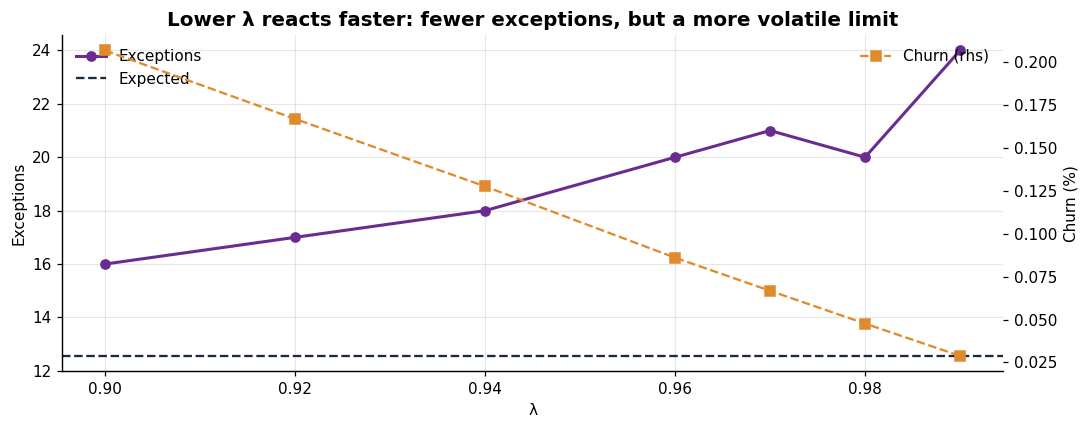

QLIKE (best variance forecast) prefers λ = 0.94. We keep λ = 0.94 as the policy value for comparability with RiskMetrics; Task 6 lets the data choose its persistence through GARCH.


In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lam_tbl['λ'], lam_tbl['Exceptions'], 'o-', color=COLORS['EWMA'], lw=2, label='Exceptions')
ax.axhline(lam_tbl['Expected'].iloc[0], color=COLORS['ink'], ls='--', label='Expected')
ax.set_xlabel('λ'); ax.set_ylabel('Exceptions'); ax.legend(loc='upper left')
ax2 = ax.twinx(); ax2.plot(lam_tbl['λ'], lam_tbl['Churn'] * 100, 's--', color=COLORS['HS'], label='Churn (rhs)')
ax2.set_ylabel('Churn (%)'); ax2.legend(loc='upper right'); ax2.grid(False)
ax.set_title('Lower λ reacts faster: fewer exceptions, but a more volatile limit'); plt.tight_layout(); plt.show()
print(f'QLIKE (best variance forecast) prefers λ = {best_q:.2f}. We keep λ = {EWMA_LAMBDA} as the policy value for '
      f'comparability with RiskMetrics; Task 6 lets the data choose its persistence through GARCH.')

## 9. Export for Tasks 6–9

In [16]:
ew_out = export_model('EWMA', EWMA, 'EWMA_VaR.csv')
pd.DataFrame({'EWMA_Vol_Daily': sigma, 'EWMA_Vol_Annualised': sigma * ann, 'Standardised_Return': returns / sigma}).to_csv('EWMA_Volatility.csv')
lam_tbl.to_csv('EWMA_Lambda_Sensitivity.csv', index=False)
update_summary(bt_ew, NEXT)
pd.read_csv(SUMMARY_FILE).query('Window == @HEADLINE_W and Confidence == @HEADLINE_CL')[
    ['Model', 'Days', 'Exceptions', 'Expected', 'Kupiec p', 'Basel zone', 'Avg VaR %', 'Next-day VaR $']]

Saved EWMA_VaR.csv (1,506 rows x 48 cols) + data dictionary
VaR_Model_Summary.csv now holds models: ['EWMA', 'GARCH', 'HS']


,Model,Days,Exceptions,Expected,Kupiec p,Basel zone,Avg VaR %,Next-day VaR $
1,GARCH,1006,14,10.0600,0.2385,GREEN,0.0347,"188,721.9343"
10,HS,1256,22,12.5600,0.0155,GREEN,0.0353,"126,797.4731"
19,EWMA,1256,18,12.5600,0.1474,GREEN,0.0373,"173,974.3428"


## 10. Executive summary

In [17]:
hh = bt_hs[(bt_hs.Window == HEADLINE_W) & (bt_hs.Confidence == HEADLINE_CL)].iloc[0]
ee = bt_ew[(bt_ew.Window == HEADLINE_W) & (bt_ew.Confidence == HEADLINE_CL)].iloc[0]
regime = s_next / sigma.iloc[SEED:].mean()
word = 'elevated' if regime > 1.15 else ('calm' if regime < 0.85 else 'normal')
ve, vh = NEXT[(HEADLINE_W, HEADLINE_CL)][0], NEXT_HS[(HEADLINE_W, HEADLINE_CL)][0]
display(Markdown(f"""
**Regime.** Tomorrow's EWMA volatility is **{pct(s_next * ann)} annualised**, {regime:.2f}x its average, so we are in a **{word}** regime.

**Headline ({HEADLINE_CL:.0%}, {HEADLINE_W}d).** Next-day EWMA-FHS VaR is **{money(ve * NAV)}**, against {money(vh * NAV)} for plain HS (**{ve / vh - 1:+.0%}**).

**Backtest.** HS: {hh.Exceptions} exceptions (Kupiec p = {hh['Kupiec p']:.3f}, {hh['Basel zone']}).
EWMA-FHS: {ee.Exceptions} exceptions (Kupiec p = {ee['Kupiec p']:.3f}, {ee['Basel zone']}). Expected: {hh.Expected:.1f}.

**What scaling bought us.** Standardised shocks show no remaining volatility clustering (Ljung–Box p = {ljung_box(z ** 2)[1]:.2f}, against
{ljung_box(r_ ** 2)[1]:.1e} for raw returns). The day after a loss larger than 3%, EWMA-FHS VaR rises **{REACT['EWMA-FHS']:+.0%}**, against {REACT['HS']:+.0%} for HS,
and {share_news:.0%} of its movement is driven by volatility news.

**What it did not fully fix.** On the 8 worst HS ghost days the jump was cut by a median **{GHOST_RED:.0%}**, but on {int((gt['Ghost reduced by'] < 0.1).sum())} of them
it was barely reduced, because a crash in a calm period is still an extreme standardised shock. The cost of faster reaction is a more volatile limit (churn {ee['VaR churn %']:.3%} vs {hh['VaR churn %']:.3%} per day).

**Limitation.** λ is imposed, not estimated, and EWMA has **no mean reversion**: a volatility spike is expected to last forever.
**Task 6** estimates the persistence and the long-run volatility with GARCH(1,1).
"""))


**Regime.** Tomorrow's EWMA volatility is **18.93% annualised**, 0.87x its average, so we are in a **normal** regime.

**Headline (99%, 250d).** Next-day EWMA-FHS VaR is **$173,974**, against $126,797 for plain HS (**+37%**).

**Backtest.** HS: 22 exceptions (Kupiec p = 0.016, GREEN).
EWMA-FHS: 18 exceptions (Kupiec p = 0.147, GREEN). Expected: 12.6.

**What scaling bought us.** Standardised shocks show no remaining volatility clustering (Ljung–Box p = 0.73, against
0.0e+00 for raw returns). The day after a loss larger than 3%, EWMA-FHS VaR rises **+19%**, against +5% for HS,
and 92% of its movement is driven by volatility news.

**What it did not fully fix.** On the 8 worst HS ghost days the jump was cut by a median **82%**, but on 2 of them
it was barely reduced, because a crash in a calm period is still an extreme standardised shock. The cost of faster reaction is a more volatile limit (churn 0.128% vs 0.009% per day).

**Limitation.** λ is imposed, not estimated, and EWMA has **no mean reversion**: a volatility spike is expected to last forever.
**Task 6** estimates the persistence and the long-run volatility with GARCH(1,1).


---
*Task 5 complete. Next: **Task 6, GARCH(1,1) volatility-scaled Historical Simulation.***

*Prepared by Arham Shah.*